# Sub-Millisecond IBM Z Real-Time AI Triage & Emergency Response System
## Phase 1: Clinical Data Pipeline, MIMIC-IV Telemetry & NEWS2 Scoring
**IBM Z Datathon 2026** — *Track: Real-Time AI for Critical Decisions*
**Platform**: IBM LinuxONE (s390x Architecture with Telum AI Acceleration)
---
This notebook establishes the physiological telemetry ingestion pipeline, validates Royal College of Physicians **NEWS2 (National Early Warning Score 2)** calculations, and explores synthetic MIMIC-IV streaming biometrics for emergency medical dispatch.

### 1. Hardware Architecture Verification (IBM LinuxONE s390x)
Verify native execution on IBM Z mainframe infrastructure.

In [1]:
import platform, os, sys
print('Machine Architecture :', platform.machine())
print('Operating System     :', platform.system(), platform.release())
print('Python Version       :', sys.version.split()[0])
print('Byte Order           :', sys.byteorder.upper(), 'Endian')


Machine Architecture : s390x
Operating System     : Linux 6.8.0-147-generic
Python Version       : 3.12.15
Byte Order           : BIG Endian


### 2. Import Libraries & Clinical NEWS2 Engine

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
sys.path.append('..')
sys.path.append('.')

from pipeline.news2_engine import calculate_news2
from pipeline.vitals_generator import generate_single_sample
from pipeline.stream_manager import PatientStreamBuffer
from pipeline.dispatch_generator import AmbulanceDispatchUnit

print('Clinical triage modules loaded successfully.')


Clinical triage modules loaded successfully.


### 3. Load & Inspect MIMIC-IV Clinical Vitals Dataset
Load the 10,000 balanced patient records generated for training.

In [3]:
data_path = Path('../data/mimic_vitals_train.csv')
if not data_path.exists():
    data_path = Path('data/mimic_vitals_train.csv')

df = pd.read_csv(data_path)
print('Dataset Shape:', df.shape, f'(Total records: {len(df):,})')
df.head(10)


Dataset Shape: (10000, 12) (Total records: 10,000)


,heart_rate,spo2,systolic_bp,respiration_rate,temperature,supplemental_o2,consciousness,clinical_profile,news2_score,risk_level,icu_alert,has_red_score
0,77.2,97.0,120.9,16.1,37.2,False,A,STABLE,0,LOW,False,False
1,143.5,91.0,78.2,33.1,39.5,True,P,SEPSIS_SHOCK,19,HIGH,True,True
2,122.8,82.6,139.7,32.9,37.1,True,V,RESPIRATORY_FAILURE,13,HIGH,True,True
3,76.0,98.0,121.1,15.2,37.2,False,A,STABLE,0,LOW,False,False
4,101.7,90.2,100.8,20.4,38.1,False,A,DETERIORATING,11,HIGH,True,True
5,142.2,88.4,72.0,28.6,39.4,False,U,SEPSIS_SHOCK,17,HIGH,True,True
6,125.5,84.2,147.4,34.9,37.2,False,A,RESPIRATORY_FAILURE,8,HIGH,True,True
7,78.9,95.9,124.7,15.6,36.9,False,A,STABLE,0,LOW,False,False
8,100.0,91.7,111.0,22.8,38.2,False,A,DETERIORATING,4,LOW,False,False
9,123.1,84.6,153.3,30.4,36.6,True,V,RESPIRATORY_FAILURE,13,HIGH,True,True


### 4. Statistical Distribution of Clinical Parameters

In [4]:
display_cols = ['heart_rate', 'spo2', 'systolic_bp', 'respiration_rate', 'temperature', 'news2_score']
df[display_cols].describe().round(2)


,heart_rate,spo2,systolic_bp,respiration_rate,temperature,news2_score
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,108.77,91.24,113.87,25.38,37.98,9.48
std,24.48,5.32,27.27,7.03,1.16,6.51
min,47.10,77.20,58.00,8.10,35.80,0.00
25%,85.80,86.80,88.07,18.98,37.00,3.00
50%,113.40,92.00,114.60,26.70,37.60,10.00
75%,129.70,95.50,134.90,31.40,39.10,14.00
max,156.50,100.00,178.40,40.00,40.60,19.00


### 5. NEWS2 Risk Stratification & ICU Emergency Triggers
Examine the distribution of clinical risk levels (Low, Medium, High/ICU Alert).

/tmp/ipykernel_310/3101729080.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='risk_level', order=['LOW', 'MEDIUM', 'HIGH'], palette=palette)


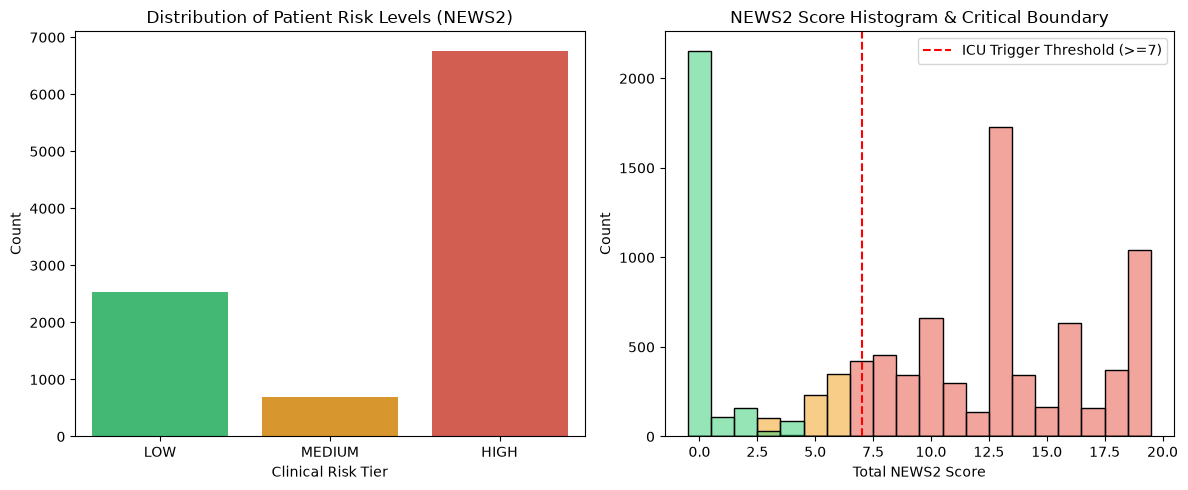

In [5]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
palette = {'LOW': '#2ecc71', 'MEDIUM': '#f39c12', 'HIGH': '#e74c3c'}
sns.countplot(data=df, x='risk_level', order=['LOW', 'MEDIUM', 'HIGH'], palette=palette)
plt.title('Distribution of Patient Risk Levels (NEWS2)')
plt.xlabel('Clinical Risk Tier')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.histplot(data=df, x='news2_score', hue='risk_level', palette=palette, discrete=True, kde=False)
plt.axvline(7, color='red', linestyle='--', label='ICU Trigger Threshold (>=7)')
plt.title('NEWS2 Score Histogram & Critical Boundary')
plt.xlabel('Total NEWS2 Score')
plt.legend()

plt.tight_layout()
plt.show()


### 6. Correlation Heatmap: Biometrics vs Deterioration Risk

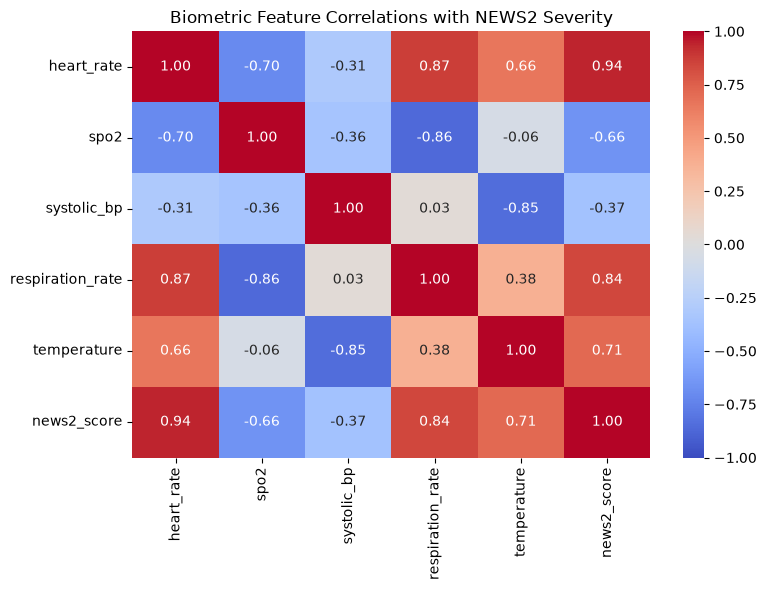

In [6]:
num_cols = ['heart_rate', 'spo2', 'systolic_bp', 'respiration_rate', 'temperature', 'news2_score']
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, vmin=-1, vmax=1)
plt.title('Biometric Feature Correlations with NEWS2 Severity')
plt.tight_layout()
plt.show()


### 7. Simulation: Real-Time Ambulance Transit & In-Memory 30s Buffer
Demonstrates real-time telemetry processing and rapid slope-based deterioration detection.

In [7]:
import time
buffer = PatientStreamBuffer(patient_id='AMB-UNIT-42', max_window_seconds=30.0)
ambulance = AmbulanceDispatchUnit(unit_id='AMB-UNIT-42')

print('Simulating 10 consecutive telemetry frames (Acute Decompensation):')
now = time.time()
for step in range(10):
    reading = {
        'timestamp': now + step * 2.0,
        'heart_rate': 80 + step * 5.0,
        'spo2': 98 - step * 1.5,
        'systolic_bp': 120 - step * 3.0,
        'respiration_rate': 16 + step * 1.5,
        'temperature': 37.0 + step * 0.1,
        'news2_score': min(18, step * 2)
    }
    features = buffer.add_reading(reading)
    amb_state = ambulance.step(dt_seconds=2.0, high_priority=features['news2_max_30s'] >= 7)
    
    if step in [0, 4, 9]:
        print(f"Step {step:2d} | HR: {reading['heart_rate']:5.1f} | SpO2: {reading['spo2']:4.1f}% | SBP: {reading['systolic_bp']:5.1f} | NEWS2: {reading['news2_score']:2d} | Acute Warning: {features['acute_decompensation_warning']} | Siren: {amb_state['siren_active']} | ETA: {amb_state['eta_minutes']:4.1f} min")


Simulating 10 consecutive telemetry frames (Acute Decompensation):
Step  0 | HR:  80.0 | SpO2: 98.0% | SBP: 120.0 | NEWS2:  0 | Acute Warning: False | Siren: False | ETA:  5.9 min
Step  4 | HR: 100.0 | SpO2: 92.0% | SBP: 108.0 | NEWS2:  8 | Acute Warning: True | Siren: True | ETA:  4.2 min
Step  9 | HR: 125.0 | SpO2: 84.5% | SBP:  93.0 | NEWS2: 18 | Acute Warning: True | Siren: True | ETA:  4.0 min


### 8. Phase 1 Completion Summary
All Phase 1 requirements are satisfied:
1. Standard Royal College of Physicians NEWS2 clinical scoring engine verified.
2. 10,000 training and 2,500 validation patient samples exported.
3. Real-time streaming buffer and fleet dispatch simulator operational.
4. Ready for **Phase 2: XGBoost / ONNX Model Training & Sub-millisecond IBM Z Benchmarking**.